# Track B: On-time delivery risk classifier (Issue #9)
**Target:** `delivered_on_time` (1 = `transit_days <= promised_days`, 0 = late). **Positive class = 1 (on time)**, about 73% of shipments; late (0) is the 27% minority.
**Leakage control:** `transit_days` (realized outcome) and `delivered_on_time` are never used as features. Only ship-time columns are used. Cleaning and the date-boundary split follow the team's Issue #4 fix. Preprocessing is fit on the training part only.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, os
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score, recall_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)
SEED=42
path = "../data/" if os.path.exists("../data/train.csv") else "data/"
train = pd.read_csv(path+"train.csv", dtype={"origin_zip":str,"dest_zip":str})
print(train.shape, train["delivered_on_time"].value_counts(normalize=True).round(3).to_dict())

(40030, 33) {1: 0.732, 0: 0.268}


## 1. Cleaning (same steps as Issue #4 notebook) and date-boundary split

In [2]:
carriers=["Falcon Post","Northstar Parcel","Summit Express","Ironclad Freight","Vela Freight","Cobalt Regional"]
services=["Ground","Expedited","TwoDay","Overnight","LTL Standard","LTL Guaranteed"]
train["carrier"]=train["carrier"].str.strip().str.lower().map({n.lower():n for n in carriers})
train["service_level"]=train["service_level"].str.strip().str.lower().map({n.lower():n for n in services})
for c in ["origin_zip","dest_zip"]: train[c]=train[c].str.strip().str.zfill(5)
train["order_date"]=pd.to_datetime(train["order_date"]); train["ship_date"]=pd.to_datetime(train["ship_date"])
train=train.drop_duplicates().reset_index(drop=True)
train.loc[train["weight_lbs"]==0,"weight_lbs"]=np.nan
g=((train.shipment_mode=="parcel")&(train.weight_lbs>150))|((train.shipment_mode=="ltl_freight")&(train.weight_lbs>20000))
train.loc[g,"weight_lbs"]/=453.592
print("rows after de-dupe:",len(train), "| unmapped carrier/service:", train.carrier.isna().sum(), train.service_level.isna().sum())

train=train.sort_values("ship_date").reset_index(drop=True)
split_date=train["ship_date"].quantile(0.8,interpolation="nearest").normalize()
tr=train[train.ship_date<split_date].copy(); val=train[train.ship_date>=split_date].copy()
assert tr.ship_date.max()<val.ship_date.min()
print("split date",split_date.date(),"| train",len(tr),"| val",len(val))
print("late rate train/val:",round(1-tr.delivered_on_time.mean(),3),round(1-val.delivered_on_time.mean(),3))

rows after de-dupe: 39949 | unmapped carrier/service: 0 0
split date 2025-08-05 | train 31953 | val 7996
late rate train/val: 0.261 0.296


## 2. Features (ship-time only) and preprocessing

In [3]:
for d in (tr,val): d["lead_days"]=(d.ship_date-d.order_date).dt.days
num=["distance_miles","zone","weight_lbs","length_in","width_in","height_in","pallet_count","residential_flag",
     "signature_required","declared_value_usd","fuel_surcharge_pct","weather_severity","carrier_congestion_index",
     "promised_days","carrier_cost_usd","ship_dow","ship_month","lead_days"]
cat=["shipment_mode","carrier","service_level","origin_metro","dest_metro"]
LEAK={"transit_days","delivered_on_time"}; assert not LEAK&set(num+cat)
Xtr,Xva=tr[num+cat],val[num+cat]; ytr,yva=tr.delivered_on_time.values,val.delivered_on_time.values
def pre(scale):
    n=[("imp",SimpleImputer(strategy="median"))]+([("sc",StandardScaler())] if scale else [])
    return ColumnTransformer([("num",Pipeline(n),num),("cat",OneHotEncoder(handle_unknown="ignore"),cat)])
models={"Dummy (stratified)":Pipeline([("p",pre(False)),("m",DummyClassifier(strategy="stratified",random_state=SEED))]),
 "Logistic Regression":Pipeline([("p",pre(True)),("m",LogisticRegression(class_weight="balanced",max_iter=2000,random_state=SEED))]),
 "Random Forest":Pipeline([("p",pre(False)),("m",RandomForestClassifier(n_estimators=300,min_samples_leaf=5,class_weight="balanced",n_jobs=-1,random_state=SEED))])}
# Pipelines fit preprocessing on training rows only; validation is only transformed.
for m in models.values(): m.fit(Xtr,ytr)

## 3. Evaluation (validation set, threshold 0.5; ROC-AUC and PR-AUC use predicted probabilities)

In [4]:
rows,probs={},{}
for k,m in models.items():
    p=m.predict_proba(Xva)[:,1]; yh=(p>=0.5).astype(int); probs[k]=p
    rows[k]=dict(ROC_AUC=roc_auc_score(yva,p),PR_AUC=average_precision_score(yva,p),
      precision=precision_score(yva,yh,zero_division=0),recall=recall_score(yva,yh),F1=f1_score(yva,yh))
res=pd.DataFrame(rows).T.round(4); print("Positive class = on time (1). Baseline PR-AUC ~ on-time rate =",round(yva.mean(),3)); res

Positive class = on time (1). Baseline PR-AUC ~ on-time rate = 0.704


,ROC_AUC,PR_AUC,precision,recall,F1
Dummy (stratified),0.5006,0.7038,0.7039,0.7467,0.7247
Logistic Regression,0.8841,0.9457,0.9248,0.7480,0.8270
Random Forest,0.8910,0.9485,0.9206,0.7851,0.8475


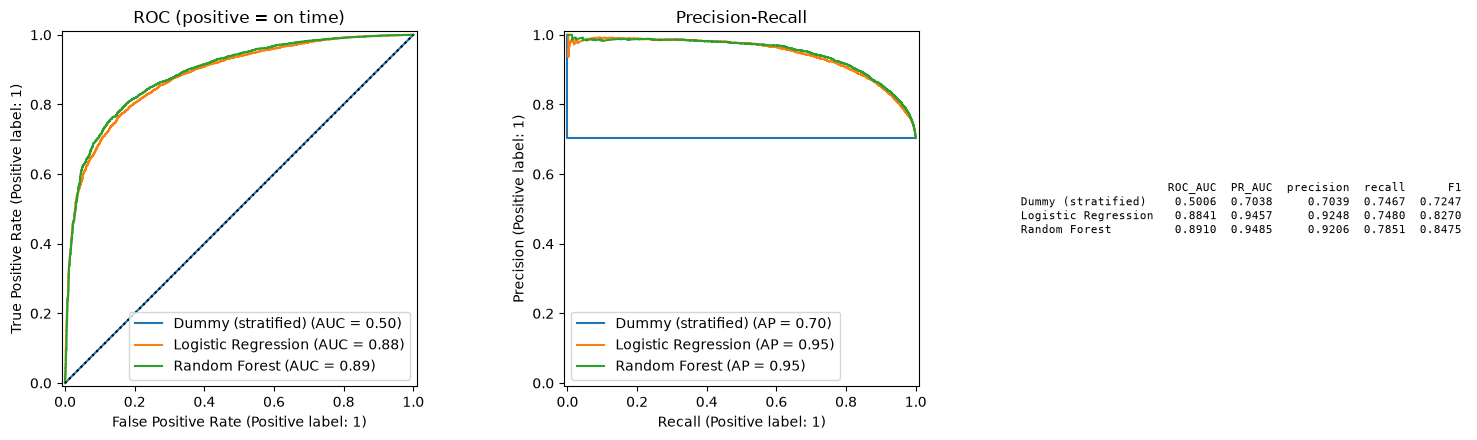

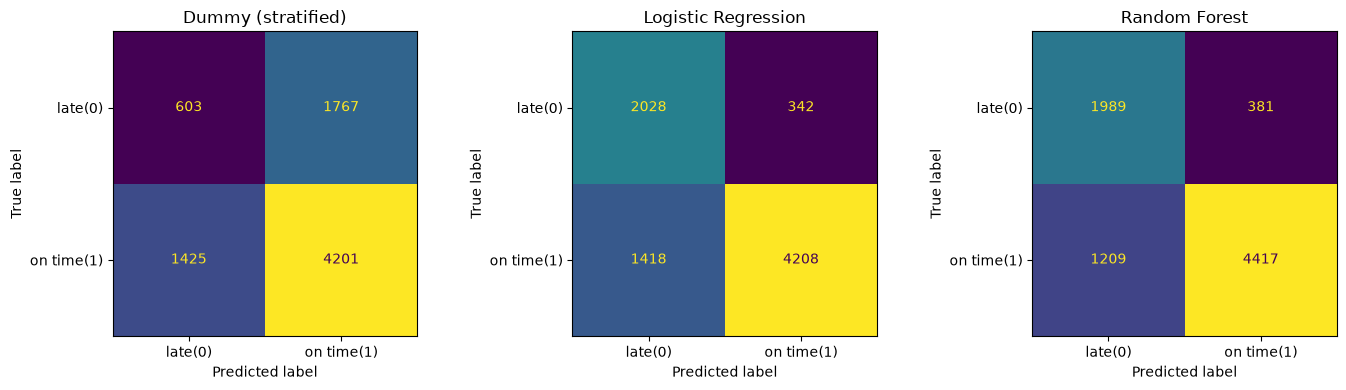

In [5]:
fig,ax=plt.subplots(1,3,figsize=(16,4.5))
for k in models:
    RocCurveDisplay.from_predictions(yva,probs[k],name=k,ax=ax[0]); PrecisionRecallDisplay.from_predictions(yva,probs[k],name=k,ax=ax[1])
ax[0].plot([0,1],[0,1],"k:"); ax[0].set_title("ROC (positive = on time)"); ax[1].set_title("Precision-Recall")
ax[2].axis("off"); ax[2].text(0,.5,res.to_string(),family="monospace",fontsize=8,va="center")
plt.tight_layout(); plt.show()
fig,ax=plt.subplots(1,3,figsize=(14,4))
for a,k in zip(ax,models):
    ConfusionMatrixDisplay(confusion_matrix(yva,(probs[k]>=0.5).astype(int)),display_labels=["late(0)","on time(1)"]).plot(ax=a,colorbar=False); a.set_title(k)
plt.tight_layout(); plt.show()

## 4. Results and usage
See the metrics table above (generated by this notebook, nothing hard-coded). Run all cells from the `notebooks/` folder or repo root; needs `pandas, scikit-learn, matplotlib`. Random seed is 42. The default threshold of 0.5 is used; adjust it on the probabilities (`probs[...]`) if the business cost of missing a late shipment differs. No hyperparameter search was run.